In [1]:
# Cohort & Customer Retention Analysis

# Objective: Understand how many customers return and continue purchasing after their first order.

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid")

In [2]:
# Cell 2 - Load datasets

import pandas as pd
from pathlib import Path

# Set correct dataset folder path
DATASET_DIR = Path("../dataset")

# Check whether dataset folder exists
print("Dataset folder exists:", DATASET_DIR.exists())

# Load CSV datasets
orders = pd.read_csv(
    DATASET_DIR / "olist_orders_dataset.csv"
)

customers = pd.read_csv(
    DATASET_DIR / "olist_customers_dataset.csv"
)

# Convert purchase timestamp into datetime
orders["order_purchase_timestamp"] = pd.to_datetime(
    orders["order_purchase_timestamp"],
    errors="coerce"
)

# Keep delivered orders only
orders = orders[
    orders["order_status"] == "delivered"
].copy()

# Remove missing purchase dates
orders = orders.dropna(
    subset=["order_purchase_timestamp"]
)

# Display dataset information
print("Orders:", orders.shape)
print("Customers:", customers.shape)

# Display first five rows
display(orders.head())
display(customers.head())

Dataset folder exists: True
Orders: (96478, 8)
Customers: (99441, 5)


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP


In [3]:
# Cell 3: Merge Customer Information

# Cell 3 - Merge customer information

# Merge orders with customer details
cohort_data = orders.merge(
    customers[["customer_id", "customer_unique_id"]],
    on="customer_id",
    how="left"
)

# Remove rows with missing customer IDs
cohort_data = cohort_data.dropna(
    subset=["customer_unique_id"]
)

# Display first five rows
display(cohort_data.head())

# Check dataset information
print("Merged dataset shape:", cohort_data.shape)

# Count unique customers
print(
    "Unique customers:",
    cohort_data["customer_unique_id"].nunique()
)

# Check missing values
print(
    "Missing customer IDs:",
    cohort_data["customer_unique_id"].isna().sum()
)

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00,7c396fd4830fd04220f754e42b4e5bff
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00,af07308b275d755c9edb36a90c618231
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00,3a653a41f6f9fc3d2a113cf8398680e8
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00,7c142cf63193a1473d2e66489a9ae977
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00,72632f0f9dd73dfee390c9b22eb56dd6


Merged dataset shape: (96478, 9)
Unique customers: 93358
Missing customer IDs: 0


In [4]:
#Cell 4: Create Purchase Month and Cohort Month
# Objective: Identify the first purchase month of every customer.

# Cell 4 - Create purchase month and cohort month

# Extract purchase month from order timestamp
cohort_data["order_month"] = (
    cohort_data["order_purchase_timestamp"]
    .dt.to_period("M")
)

# Find the first purchase month for each customer
cohort_data["cohort_month"] = (
    cohort_data.groupby("customer_unique_id")["order_month"]
    .transform("min")
)

# Display customer cohort information
display(
    cohort_data[
        [
            "customer_unique_id",
            "order_purchase_timestamp",
            "order_month",
            "cohort_month"
        ]
    ].head(10)
)

print("Purchase month and cohort month created successfully!")

,customer_unique_id,order_purchase_timestamp,order_month,cohort_month
0,7c396fd4830fd04220f754e42b4e5bff,2017-10-02 10:56:33,2017-10,2017-09
1,af07308b275d755c9edb36a90c618231,2018-07-24 20:41:37,2018-07,2018-07
2,3a653a41f6f9fc3d2a113cf8398680e8,2018-08-08 08:38:49,2018-08,2018-08
3,7c142cf63193a1473d2e66489a9ae977,2017-11-18 19:28:06,2017-11,2017-11
4,72632f0f9dd73dfee390c9b22eb56dd6,2018-02-13 21:18:39,2018-02,2018-02
5,80bb27c7c16e8f973207a5086ab329e2,2017-07-09 21:57:05,2017-07,2017-07
6,932afa1e708222e5821dac9cd5db4cae,2017-05-16 13:10:30,2017-05,2017-05
7,39382392765b6dc74812866ee5ee92a7,2017-01-23 18:29:09,2017-01,2017-01
8,299905e3934e9e181bfb2e164dd4b4f8,2017-07-29 11:55:02,2017-07,2017-07
9,f2a85dec752b8517b5e58a06ff3cd937,2017-05-16 19:41:10,2017-05,2017-05


Purchase month and cohort month created successfully!


In [5]:
#Cell 5: Calculate Cohort Index
#Objective: Calculate how many months have passed since the customer's first purchase. 

# Cell 5 - Calculate cohort index

# Extract order year and month
order_year = cohort_data["order_month"].dt.year
order_month = cohort_data["order_month"].dt.month

# Extract cohort year and month
cohort_year = cohort_data["cohort_month"].dt.year
cohort_month = cohort_data["cohort_month"].dt.month

# Calculate cohort index
cohort_data["cohort_index"] = (
    (order_year - cohort_year) * 12
    + (order_month - cohort_month)
    + 1
)

# Display results
display(
    cohort_data[
        [
            "customer_unique_id",
            "order_month",
            "cohort_month",
            "cohort_index"
        ]
    ].head(10)
)

print("Cohort index calculated successfully!")

,customer_unique_id,order_month,cohort_month,cohort_index
0,7c396fd4830fd04220f754e42b4e5bff,2017-10,2017-09,2
1,af07308b275d755c9edb36a90c618231,2018-07,2018-07,1
2,3a653a41f6f9fc3d2a113cf8398680e8,2018-08,2018-08,1
3,7c142cf63193a1473d2e66489a9ae977,2017-11,2017-11,1
4,72632f0f9dd73dfee390c9b22eb56dd6,2018-02,2018-02,1
5,80bb27c7c16e8f973207a5086ab329e2,2017-07,2017-07,1
6,932afa1e708222e5821dac9cd5db4cae,2017-05,2017-05,1
7,39382392765b6dc74812866ee5ee92a7,2017-01,2017-01,1
8,299905e3934e9e181bfb2e164dd4b4f8,2017-07,2017-07,1
9,f2a85dec752b8517b5e58a06ff3cd937,2017-05,2017-05,1


Cohort index calculated successfully!


In [6]:
# Cell 6: Cohort Retention Table
# Objective: Calculate how many customers return in each month after their first purchase.

# Cell 6 - Create Cohort Retention Table

# Count unique customers for each cohort month and cohort index
cohort_table = cohort_data.groupby(
    ["cohort_month", "cohort_index"]
)["customer_unique_id"].nunique().reset_index()

# Convert data into a pivot table
cohort_pivot = cohort_table.pivot(
    index="cohort_month",
    columns="cohort_index",
    values="customer_unique_id"
)

# Display cohort table
display(cohort_pivot)

print("Cohort retention table created successfully!")

cohort_index,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,20,21
cohort_month,,,,,,,,,,,,,,,,,,,,
2016-09,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2016-10,262.0,NaN,NaN,NaN,NaN,NaN,1.0,NaN,NaN,1.0,NaN,1.0,NaN,1.0,NaN,1.0,NaN,1.0,2.0,2.0
2016-12,1.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2017-01,717.0,2.0,2.0,1.0,3.0,1.0,3.0,1.0,1.0,NaN,3.0,1.0,5.0,3.0,1.0,1.0,2.0,3.0,1.0,NaN
2017-02,1628.0,3.0,5.0,2.0,7.0,2.0,4.0,3.0,2.0,3.0,2.0,5.0,2.0,3.0,2.0,1.0,1.0,3.0,NaN,NaN
2017-03,2503.0,11.0,9.0,10.0,9.0,4.0,4.0,8.0,8.0,2.0,9.0,3.0,5.0,3.0,4.0,6.0,2.0,3.0,NaN,NaN
2017-04,2256.0,14.0,5.0,4.0,6.0,6.0,8.0,7.0,7.0,4.0,6.0,2.0,1.0,1.0,2.0,2.0,3.0,NaN,NaN,NaN
2017-05,3451.0,16.0,16.0,10.0,10.0,11.0,14.0,5.0,9.0,9.0,9.0,12.0,8.0,1.0,6.0,7.0,NaN,NaN,NaN,NaN
2017-06,3037.0,15.0,12.0,13.0,9.0,12.0,11.0,7.0,4.0,6.0,9.0,11.0,5.0,5.0,7.0,NaN,NaN,NaN,NaN,NaN


Cohort retention table created successfully!


In [7]:
# Cell 7: Calculate Retention Percentage

# Cell 7 - Calculate Retention Percentage

# Get the number of customers in the first month
cohort_size = cohort_pivot.iloc[:, 0]

# Calculate retention percentage
retention_table = cohort_pivot.divide(
    cohort_size,
    axis=0
) * 100

# Round percentages
retention_table = retention_table.round(2)

# Display retention table
display(retention_table)

print("Retention percentage calculated successfully!")

cohort_index,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,20,21
cohort_month,,,,,,,,,,,,,,,,,,,,
2016-09,100.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2016-10,100.0,NaN,NaN,NaN,NaN,NaN,0.38,NaN,NaN,0.38,NaN,0.38,NaN,0.38,NaN,0.38,NaN,0.38,0.76,0.76
2016-12,100.0,100.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2017-01,100.0,0.28,0.28,0.14,0.42,0.14,0.42,0.14,0.14,NaN,0.42,0.14,0.70,0.42,0.14,0.14,0.28,0.42,0.14,NaN
2017-02,100.0,0.18,0.31,0.12,0.43,0.12,0.25,0.18,0.12,0.18,0.12,0.31,0.12,0.18,0.12,0.06,0.06,0.18,NaN,NaN
2017-03,100.0,0.44,0.36,0.40,0.36,0.16,0.16,0.32,0.32,0.08,0.36,0.12,0.20,0.12,0.16,0.24,0.08,0.12,NaN,NaN
2017-04,100.0,0.62,0.22,0.18,0.27,0.27,0.35,0.31,0.31,0.18,0.27,0.09,0.04,0.04,0.09,0.09,0.13,NaN,NaN,NaN
2017-05,100.0,0.46,0.46,0.29,0.29,0.32,0.41,0.14,0.26,0.26,0.26,0.35,0.23,0.03,0.17,0.20,NaN,NaN,NaN,NaN
2017-06,100.0,0.49,0.40,0.43,0.30,0.40,0.36,0.23,0.13,0.20,0.30,0.36,0.16,0.16,0.23,NaN,NaN,NaN,NaN,NaN


Retention percentage calculated successfully!


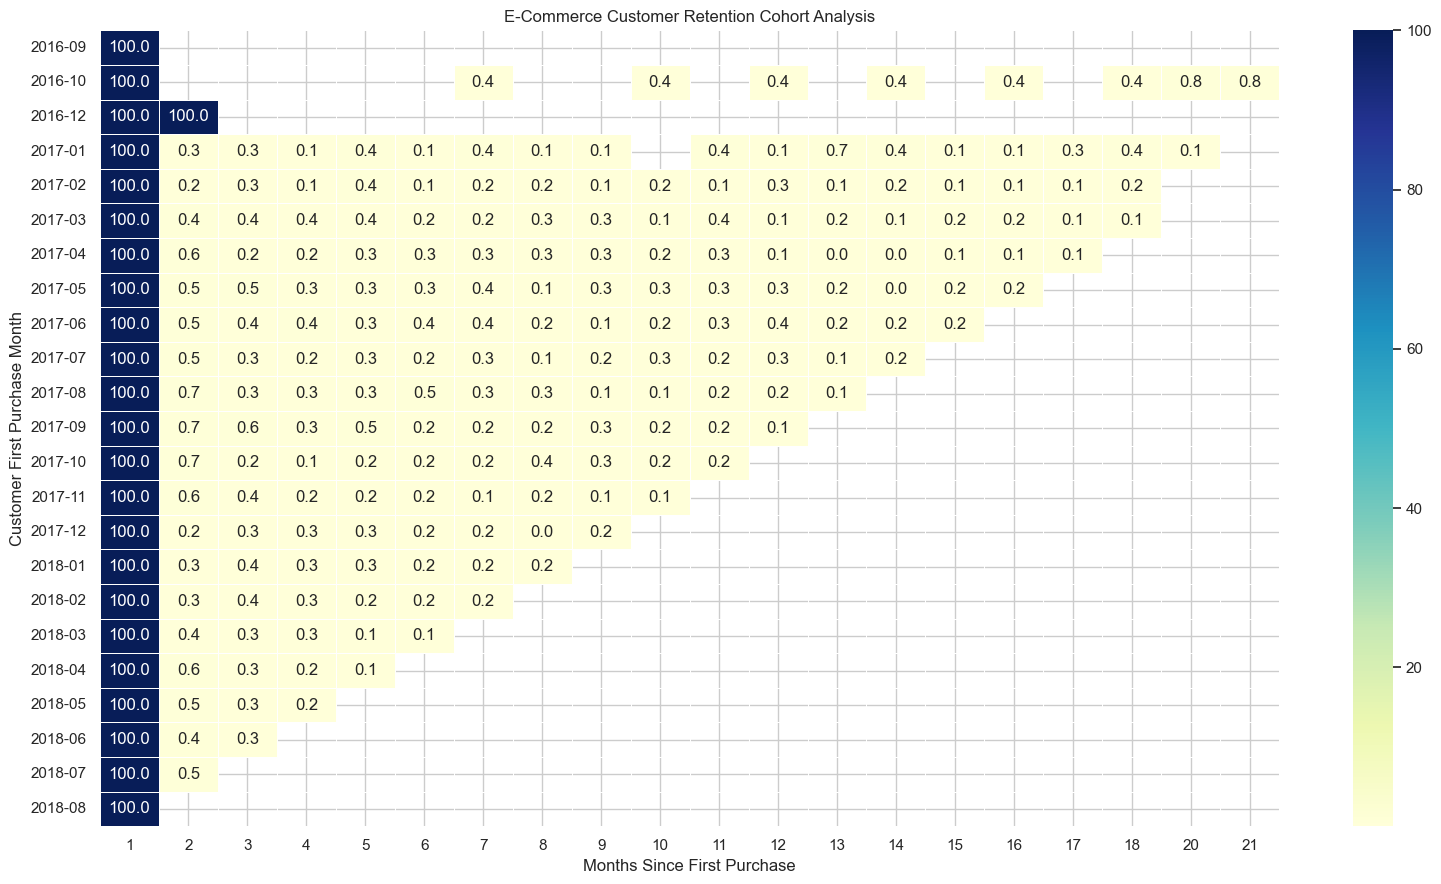

In [8]:
# Cell 8: Create Retention Heatmap

# Cell 8 - Customer Retention Heatmap
import matplotlib.pyplot as plt

plt.figure(figsize=(16, 9))

sns.heatmap(
    retention_table,
    annot=True,
    fmt=".1f",
    cmap="YlGnBu",
    linewidths=0.5
)

plt.title("E-Commerce Customer Retention Cohort Analysis")
plt.xlabel("Months Since First Purchase")
plt.ylabel("Customer First Purchase Month")

plt.tight_layout()

# Save chart
plt.savefig(
    "../screenshots/06_cohort_retention_heatmap.png",
    dpi=300
)

plt.show()

In [9]:
# Import Path library
from pathlib import Path

# Define processed folder path
processed_path = Path("../processed")

# Check customer cohort data file
customer_file = processed_path / "customer_cohort_data.csv"

# Check cohort customer counts file
counts_file = processed_path / "cohort_customer_counts.csv"

# Check retention percentage file
retention_file = processed_path / "cohort_retention_percentage.csv"

# Display customer cohort data status
print("Customer Cohort Data:", customer_file.exists())

# Display cohort customer counts status
print("Cohort Customer Counts:", counts_file.exists())

# Display retention percentage status
print("Retention Percentages:", retention_file.exists())

# Display completion message
print("STEP 06 FILE VERIFICATION COMPLETED!")

Customer Cohort Data: True
Cohort Customer Counts: True
Retention Percentages: True
STEP 06 FILE VERIFICATION COMPLETED!
